# Analysis of the frame-stacking study

This notebook reads the training logs produced by `train_ppo.ipynb` and generates every
figure and table used in the report. **No GPU is required** — everything here runs on CPU
(the saliency maps load the saved models for a few forward passes only).

**Inputs expected**
- `results/ppo_history_<game>_fs<N>_seed<s>.csv` — one per run (**45 runs**).
- `models/ppo_<game>_fs<N>_seed0.pt` — saved networks (only needed for the saliency section).

**Experimental grid**
`FRAME_STACK ∈ {1, 2, 4, 8, 16}` × `GAME ∈ {Breakout, SpaceInvaders, Pong}` ×
`SEED ∈ {0, 1, 2}` = **45 runs**, 2M environment steps each.

**What it produces**
1. Learning curves per game (one line per frame setting, mean ± std over seeds).
2. Final performance vs number of frames (RQ1).
3. Sample efficiency, AUC and stability metrics.
4. Summary tables (pasted into the report).
5. Statistical significance: bootstrap confidence intervals + permutation tests.
6. Cost–performance (Pareto) analysis.
7. Saliency maps (gradient and perturbation methods).


## 0. Configuration

In [5]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR  = "results"
MODEL_DIR = "models"
FIG_DIR   = "figures"
OUT_DIR   = "results"
os.makedirs(FIG_DIR, exist_ok=True)

GAMES  = ["Breakout", "SpaceInvaders", "Pong"]
FRAMES = [1, 2, 4, 8, 16]
SEEDS  = [0, 1, 2]

def load(game, fs, seed):
    p = os.path.join(DATA_DIR, f"ppo_history_{game}_fs{fs}_seed{seed}.csv")
    return pd.read_csv(p) if os.path.exists(p) else None

found = sum(load(g, fs, s) is not None
            for g in GAMES for fs in FRAMES for s in SEEDS)
print(f"found {found} / {len(GAMES)*len(FRAMES)*len(SEEDS)} runs in '{DATA_DIR}/'")


found 45 / 45 runs in '/kaggle/input/datasets/kawtarelgueddari/dataset2/'


## 1. Learning curves per game (one line per frame setting, seeds averaged)

To average across seeds that may log at slightly different steps, each run's reward is
interpolated onto a common step grid, then we take mean and std across seeds (shaded band).

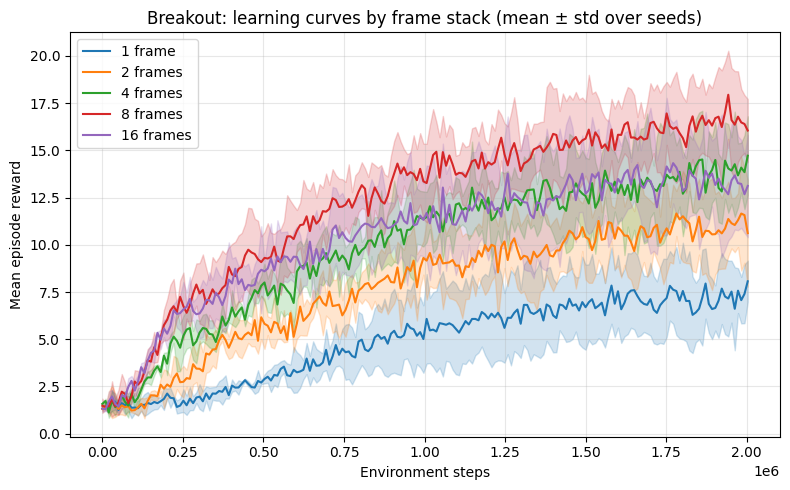

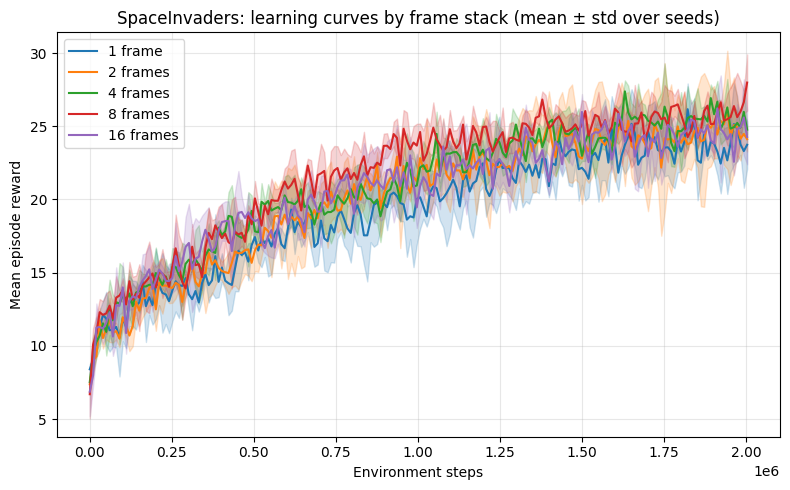

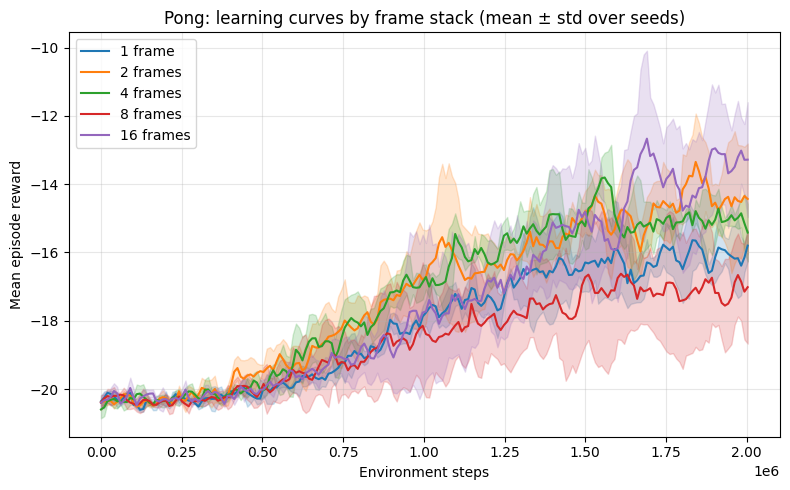

In [6]:
def seed_mean_std(game, fs, n_points=200):
    """Interpolate each seed's reward onto a common grid, return (grid, mean, std)."""
    curves = []
    for s in SEEDS:
        df = load(game, fs, s)
        if df is None: continue
        d = df.dropna(subset=["mean_reward"])
        if len(d) < 2: continue
        curves.append((d["step"].values, d["mean_reward"].values))
    if not curves: return None
    xmax = min(c[0].max() for c in curves)
    grid = np.linspace(0, xmax, n_points)
    stack = np.stack([np.interp(grid, x, y) for x, y in curves])
    return grid, stack.mean(0), stack.std(0)

for game in GAMES:
    plt.figure(figsize=(8, 5))
    for fs in FRAMES:
        res = seed_mean_std(game, fs)
        if res is None: continue
        grid, mean, std = res
        line, = plt.plot(grid, mean, label=f"{fs} frame" + ("s" if fs > 1 else ""))
        plt.fill_between(grid, mean - std, mean + std, alpha=0.2, color=line.get_color())
    plt.title(f"{game}: learning curves by frame stack (mean ± std over seeds)")
    plt.xlabel("Environment steps"); plt.ylabel("Mean episode reward")
    plt.grid(True, alpha=0.3); plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"curves_{game}.png"), dpi=150, bbox_inches="tight")
    plt.show()


## 2. Final performance vs number of frames (RQ1)

Final reward = average of the last 10% of each run, then mean ± std over seeds.

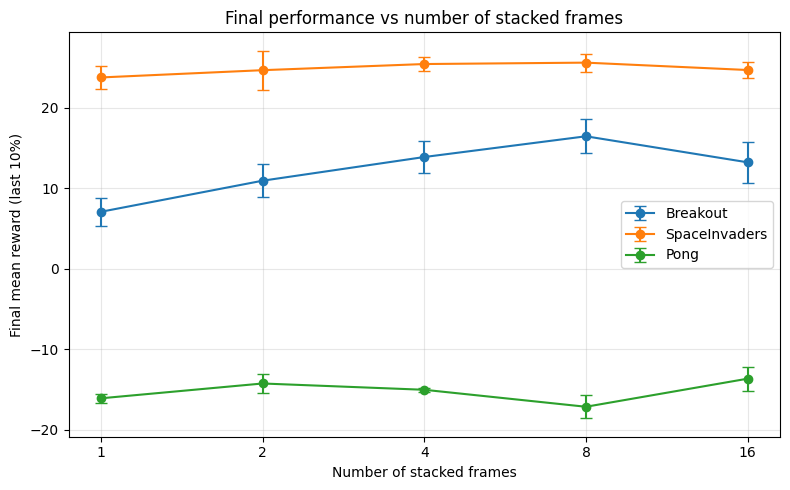

In [7]:
def final_reward(game, fs):
    vals = []
    for s in SEEDS:
        df = load(game, fs, s)
        if df is None: continue
        d = df["mean_reward"].dropna().values
        if len(d) == 0: continue
        tail = d[max(0, int(len(d) * 0.9)):]   # last 10%
        vals.append(tail.mean())
    if not vals: return np.nan, np.nan
    return np.mean(vals), np.std(vals)

plt.figure(figsize=(8, 5))
for game in GAMES:
    means, stds = [], []
    for fs in FRAMES:
        m, sd = final_reward(game, fs); means.append(m); stds.append(sd)
    plt.errorbar(FRAMES, means, yerr=stds, marker="o", capsize=4, label=game)
plt.xscale("log", base=2); plt.xticks(FRAMES, FRAMES)
plt.title("Final performance vs number of stacked frames")
plt.xlabel("Number of stacked frames"); plt.ylabel("Final mean reward (last 10%)")
plt.grid(True, alpha=0.3); plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "final_vs_frames.png"), dpi=150, bbox_inches="tight")
plt.show()


## 3. Efficiency, AUC and stability metrics

For each config we compute: final reward (mean/std over seeds), coefficient of variation
(stability), area under the learning curve (AUC), and sample efficiency (steps to reach a
per-game target reward). These feed the metrics table and the efficiency/AUC figures.

In [9]:
# per-game target for the "steps to target" sample-efficiency metric
TARGETS = {"Breakout": 10.0, "SpaceInvaders": 22.0, "Pong": -15.0}

rows = []
for game in GAMES:
    for fs in FRAMES:
        finals, aucs, steps_to_tgt = [], [], []
        for s in SEEDS:
            df = load(game, fs, s)
            if df is None: continue
            d = df.dropna(subset=["mean_reward"])
            r = d["mean_reward"].values
            st = d["step"].values
            finals.append(r[int(len(r) * 0.9):].mean())
            aucs.append(np.trapz(r, st) / (st[-1] - st[0]))
            hit = d[d["mean_reward"] >= TARGETS[game]]
            steps_to_tgt.append(hit["step"].iloc[0] if len(hit) else np.nan)
        if not finals: continue
        finals = np.array(finals); aucs = np.array(aucs)
        reached = [x for x in steps_to_tgt if not np.isnan(x)]
        rows.append({
            "game": game, "frames": fs,
            "final_mean": round(finals.mean(), 2),
            "final_std":  round(finals.std(), 2),
            "cv_%":       round(abs(100 * finals.std() / finals.mean()), 1),
            "AUC":        round(aucs.mean(), 2),
            "steps_to_target_k": (round(np.mean(reached) / 1000) if reached else None),
            "seeds_reached": f"{len(reached)}/{len(steps_to_tgt)}",
        })

summary = pd.DataFrame(rows)
pd.set_option("display.width", 200)
print("TARGETS:", TARGETS)
print(summary.to_string(index=False))
summary.to_csv(os.path.join(OUT_DIR, "metrics_summary.csv"), index=False)


/tmp/ipykernel_49/322943714.py:15: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  aucs.append(np.trapz(r, st) / (st[-1] - st[0]))
/tmp/ipykernel_49/322943714.py:15: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  aucs.append(np.trapz(r, st) / (st[-1] - st[0]))
/tmp/ipykernel_49/322943714.py:15: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  aucs.append(np.trapz(r, st) / (st[-1] - st[0]))
/tmp/ipykernel_49/322943714.py:15: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  aucs.append(np.trapz(r, st) / (st[-1] - st[0]))
/tmp/ipykernel_49/322943714.py:15: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the

TARGETS: {'Breakout': 10.0, 'SpaceInvaders': 22.0, 'Pong': -15.0}
         game  frames  final_mean  final_std  cv_%    AUC  steps_to_target_k seeds_reached
     Breakout       1        7.10       1.76  24.8   4.88               1487           1/3
     Breakout       2       10.96       2.08  19.0   7.69               1184           3/3
     Breakout       4       13.91       1.99  14.3   9.87                743           3/3
     Breakout       8       16.48       2.13  12.9  12.19                452           3/3
     Breakout      16       13.25       2.51  18.9  10.36                517           3/3
SpaceInvaders       1       23.79       1.42   6.0  19.29                901           3/3
SpaceInvaders       2       24.70       2.42   9.8  20.18                692           3/3
SpaceInvaders       4       25.46       0.83   3.2  20.89                526           3/3
SpaceInvaders       8       25.64       1.12   4.4  21.69                603           3/3
SpaceInvaders      16   

/tmp/ipykernel_49/322943714.py:15: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  aucs.append(np.trapz(r, st) / (st[-1] - st[0]))
/tmp/ipykernel_49/322943714.py:15: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  aucs.append(np.trapz(r, st) / (st[-1] - st[0]))
/tmp/ipykernel_49/322943714.py:15: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  aucs.append(np.trapz(r, st) / (st[-1] - st[0]))
/tmp/ipykernel_49/322943714.py:15: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  aucs.append(np.trapz(r, st) / (st[-1] - st[0]))
/tmp/ipykernel_49/322943714.py:15: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the

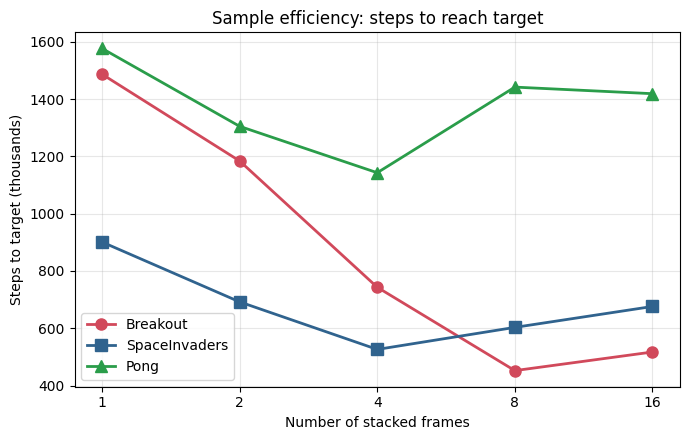

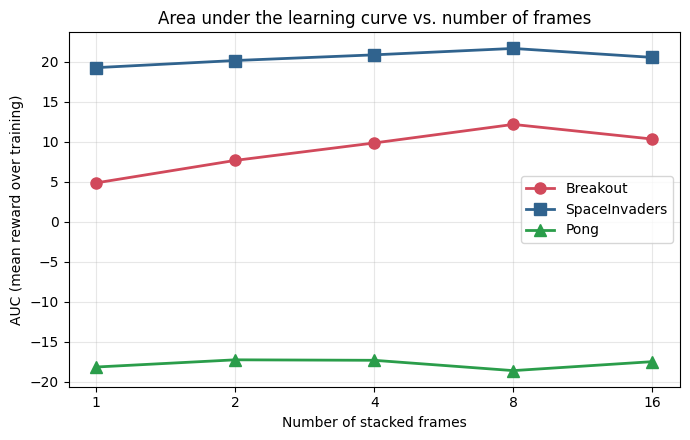

In [10]:
plt.figure(figsize=(7, 4.5))
for game, c, m in [("Breakout", "#d1495b", "o"), ("SpaceInvaders", "#30638e", "s"), ("Pong", "#2a9d4a", "^")]:
    sub = summary[summary.game == game]
    plt.plot(sub["frames"], sub["steps_to_target_k"].astype(float),
             marker=m, lw=2, markersize=8, label=game, color=c)
plt.xscale("log", base=2); plt.xticks(FRAMES, FRAMES)
plt.xlabel("Number of stacked frames"); plt.ylabel("Steps to target (thousands)")
plt.title("Sample efficiency: steps to reach target")
plt.grid(True, alpha=0.3); plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "sample_efficiency.png"), dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 4.5))
for game, c, m in [("Breakout", "#d1495b", "o"), ("SpaceInvaders", "#30638e", "s"), ("Pong", "#2a9d4a", "^")]:
    sub = summary[summary.game == game]
    plt.plot(sub["frames"], sub["AUC"], marker=m, lw=2, markersize=8, label=game, color=c)
plt.xscale("log", base=2); plt.xticks(FRAMES, FRAMES)
plt.xlabel("Number of stacked frames"); plt.ylabel("AUC (mean reward over training)")
plt.title("Area under the learning curve vs. number of frames")
plt.grid(True, alpha=0.3); plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "auc_vs_frames.png"), dpi=150, bbox_inches="tight")
plt.show()


## 4. Statistical significance (bootstrap CI + permutation tests)

With only three seeds per config, differences could be seed noise. We report a 95% bootstrap
confidence interval for each config's final reward, and two-sided permutation tests on the key
comparisons. Note: three-vs-three permutation tests cannot return p below ~0.1, so
non-significant p-values reflect low statistical power, not absence of effect.

In [11]:
rng = np.random.default_rng(0)

def final_scores(game, fs):
    """Final score (mean of last 10%) for each seed -> array."""
    vals = []
    for s in SEEDS:
        df = load(game, fs, s)
        if df is None: continue
        r = df["mean_reward"].dropna().values
        if len(r) == 0: continue
        vals.append(r[int(len(r) * 0.9):].mean())
    return np.array(vals)

def bootstrap_ci(vals, n=10000, alpha=0.05):
    if len(vals) < 2: return (np.nan, np.nan)
    boot = [rng.choice(vals, size=len(vals), replace=True).mean() for _ in range(n)]
    lo, hi = np.percentile(boot, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return lo, hi

print("=" * 60); print("BOOTSTRAP 95% CONFIDENCE INTERVALS (final reward)"); print("=" * 60)
rows = []
for game in GAMES:
    for fs in FRAMES:
        v = final_scores(game, fs)
        lo, hi = bootstrap_ci(v)
        rows.append({"game": game, "frames": fs, "mean": round(v.mean(), 2),
                     "CI95_low": round(lo, 2), "CI95_high": round(hi, 2), "n_seeds": len(v)})
ci_df = pd.DataFrame(rows)
print(ci_df.to_string(index=False))

def perm_test(a, b, n=20000):
    """Two-sided p-value: prob. of a mean difference as large as observed under H0."""
    obs = abs(a.mean() - b.mean())
    pool = np.concatenate([a, b]); na = len(a); count = 0
    for _ in range(n):
        rng.shuffle(pool)
        if abs(pool[:na].mean() - pool[na:].mean()) >= obs: count += 1
    return (count + 1) / (n + 1)

print("\n" + "=" * 60); print("PERMUTATION TESTS (two-sided p-values)"); print("=" * 60)
comparisons = [("Breakout", 1, 8), ("Breakout", 8, 16), ("Breakout", 4, 8), ("SpaceInvaders", 1, 8)]
for game, f1, f2 in comparisons:
    a, b = final_scores(game, f1), final_scores(game, f2)
    p = perm_test(a, b)
    sig = "significant (p<0.05)" if p < 0.05 else "NOT significant (p>=0.05)"
    print(f"{game}: fs{f1} ({a.mean():.1f}) vs fs{f2} ({b.mean():.1f})  ->  p = {p:.3f}  [{sig}]")


BOOTSTRAP 95% CONFIDENCE INTERVALS (final reward)
         game  frames   mean  CI95_low  CI95_high  n_seeds
     Breakout       1   7.10      4.93       9.23        3
     Breakout       2  10.96      8.35      13.44        3
     Breakout       4  13.91     11.53      16.41        3
     Breakout       8  16.48     13.61      18.68        3
     Breakout      16  13.25     10.18      16.32        3
SpaceInvaders       1  23.79     21.98      25.45        3
SpaceInvaders       2  24.70     21.28      26.56        3
SpaceInvaders       4  25.46     24.54      26.54        3
SpaceInvaders       8  25.64     24.12      26.77        3
SpaceInvaders      16  24.72     23.48      25.86        3
         Pong       1 -16.08    -16.50     -15.29        3
         Pong       2 -14.24    -15.08     -12.56        3
         Pong       4 -15.02    -15.36     -14.74        3
         Pong       8 -17.13    -18.19     -15.10        3
         Pong      16 -13.64    -15.25     -11.66        3

PERMU

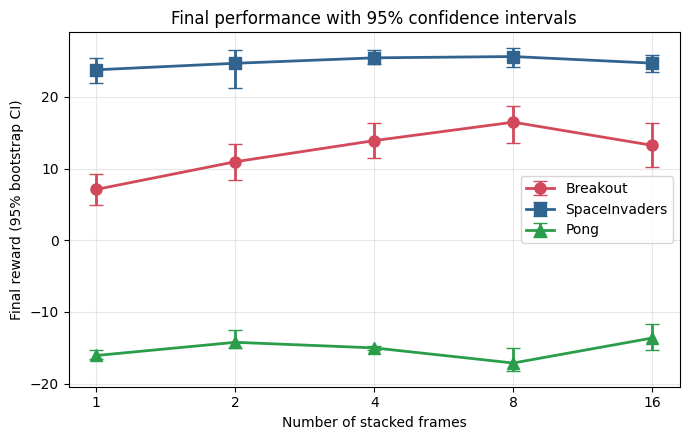

In [12]:
plt.figure(figsize=(7, 4.5))
for game, c, m in [("Breakout", "#d1495b", "o"), ("SpaceInvaders", "#30638e", "s"), ("Pong", "#2a9d4a", "^")]:
    sub = ci_df[ci_df.game == game]
    x = sub["frames"].values; y = sub["mean"].values
    lo = y - sub["CI95_low"].values; hi = sub["CI95_high"].values - y
    plt.errorbar(x, y, yerr=[lo, hi], marker=m, lw=2, markersize=8, capsize=5, label=game, color=c)
plt.xscale("log", base=2); plt.xticks(FRAMES, FRAMES)
plt.xlabel("Number of stacked frames"); plt.ylabel("Final reward (95% bootstrap CI)")
plt.title("Final performance with 95% confidence intervals")
plt.grid(True, alpha=0.3); plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "final_with_ci.png"), dpi=150, bbox_inches="tight")
plt.show()


## 5. Cost–performance (Pareto) analysis

Using the number of stacked frames as a proxy for input cost, we plot final reward against
cost for the two converged games and identify the Pareto front.

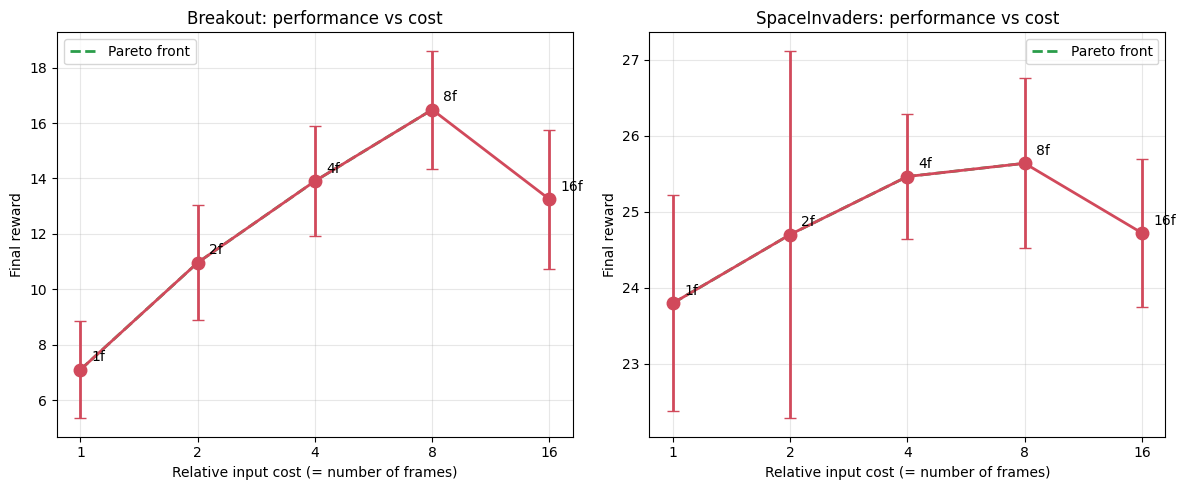

Efficiency = final reward / input cost  (higher = better value)

Breakout:
  fs 1: reward=  7.1  cost=x1   reward/cost= 7.10
  fs 2: reward= 11.0  cost=x2   reward/cost= 5.48
  fs 4: reward= 13.9  cost=x4   reward/cost= 3.48
  fs 8: reward= 16.5  cost=x8   reward/cost= 2.06
  fs16: reward= 13.2  cost=x16  reward/cost= 0.83

SpaceInvaders:
  fs 1: reward= 23.8  cost=x1   reward/cost=23.79
  fs 2: reward= 24.7  cost=x2   reward/cost=12.35
  fs 4: reward= 25.5  cost=x4   reward/cost= 6.37
  fs 8: reward= 25.6  cost=x8   reward/cost= 3.20
  fs16: reward= 24.7  cost=x16  reward/cost= 1.54


In [13]:
# final performance (mean, std) per game and frame count, read from the metrics computed above
perf = {}
for game in ["Breakout", "SpaceInvaders"]:
    perf[game] = {fs: final_reward(game, fs) for fs in FRAMES}

cost = {fs: fs for fs in FRAMES}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, game in zip(axes, ["Breakout", "SpaceInvaders"]):
    xs = [cost[fs] for fs in FRAMES]
    ys = [perf[game][fs][0] for fs in FRAMES]
    es = [perf[game][fs][1] for fs in FRAMES]
    ax.errorbar(xs, ys, yerr=es, marker="o", lw=2, markersize=9, capsize=4, color="#d1495b")
    for fs in FRAMES:
        ax.annotate(f"{fs}f", (cost[fs], perf[game][fs][0]),
                    textcoords="offset points", xytext=(8, 6), fontsize=10)
    best = -np.inf; pf_x = []; pf_y = []
    for fs in FRAMES:
        if perf[game][fs][0] > best:
            best = perf[game][fs][0]; pf_x.append(cost[fs]); pf_y.append(perf[game][fs][0])
    ax.plot(pf_x, pf_y, "--", color="#2a9d4a", lw=2, label="Pareto front")
    ax.set_xscale("log", base=2); ax.set_xticks(FRAMES); ax.set_xticklabels(FRAMES)
    ax.set_xlabel("Relative input cost (= number of frames)")
    ax.set_ylabel("Final reward"); ax.set_title(f"{game}: performance vs cost")
    ax.grid(True, alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "pareto.png"), dpi=150, bbox_inches="tight")
plt.show()

print("Efficiency = final reward / input cost  (higher = better value)")
for game in ["Breakout", "SpaceInvaders"]:
    print(f"\n{game}:")
    for fs in FRAMES:
        r = perf[game][fs][0] / cost[fs]
        print(f"  fs{fs:2d}: reward={perf[game][fs][0]:5.1f}  cost=x{fs:<2d}  reward/cost={r:5.2f}")


## 6. Saliency maps

The next cells need the saved models in `MODEL_DIR` (`ppo_<game>_fs<N>_seed0.pt`). They run on
CPU. First a shared block of helpers (network, env, model loading, rolling out an observation),
then the two saliency methods.

In [16]:
import torch
import torch.nn as nn
from torch.distributions import Categorical
import gymnasium as gym
import ale_py
gym.register_envs(ale_py)

IMG_SIZE = 84
FRAME_SKIP = 4
sal_device = torch.device("cpu")

class ActorCritic(nn.Module):
    """Same architecture as training, to load the weights."""
    def __init__(self, in_channels, n_actions):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(in_channels, 32, 8, 4), nn.ReLU(),
            nn.Conv2d(32, 64, 4, 2), nn.ReLU(),
            nn.Conv2d(64, 64, 3, 1), nn.ReLU(), nn.Flatten())
        with torch.no_grad():
            n = self.body(torch.zeros(1, in_channels, IMG_SIZE, IMG_SIZE)).shape[1]
        self.hidden = nn.Sequential(nn.Linear(n, 256), nn.ReLU())
        self.actor = nn.Linear(256, n_actions)
        self.critic = nn.Linear(256, 1)
    def forward(self, x):
        x = x.float() / 255.0
        h = self.hidden(self.body(x))
        return self.actor(h), self.critic(h).squeeze(-1)

def make_env(game, frame_stack, seed=0):
    from gymnasium.wrappers import AtariPreprocessing, FrameStackObservation
    env = gym.make(f"ALE/{game}-v5", frameskip=1)
    env = AtariPreprocessing(env, frame_skip=FRAME_SKIP, screen_size=IMG_SIZE,
                             grayscale_obs=True, scale_obs=False)
    return FrameStackObservation(env, stack_size=frame_stack)

def load_model(game, frame_stack):
    env = make_env(game, frame_stack); n_actions = env.action_space.n; env.close()
    model = ActorCritic(frame_stack, n_actions).to(sal_device)
    path = os.path.join(MODEL_DIR, f"ppo_{game}_fs{frame_stack}_seed0.pt")
    model.load_state_dict(torch.load(path, map_location=sal_device))
    model.eval()
    return model

def get_observation(game, frame_stack, warmup=60, seed=0):
    """Play a few steps with the trained policy to reach an interesting game state."""
    env = make_env(game, frame_stack, seed); model = load_model(game, frame_stack)
    obs, _ = env.reset(seed=seed)
    for _ in range(warmup):
        x = torch.from_numpy(np.asarray(obs, dtype=np.uint8)).unsqueeze(0).to(sal_device)
        with torch.no_grad():
            logits, _ = model(x)
        a = Categorical(logits=logits).sample().item()
        obs, r, term, trunc, _ = env.step(a)
        if term or trunc:
            obs, _ = env.reset()
    env.close()
    return np.asarray(obs, dtype=np.uint8)   # (frame_stack, 84, 84)


### 6a. Gradient saliency (Simonyan et al. 2014)

A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]


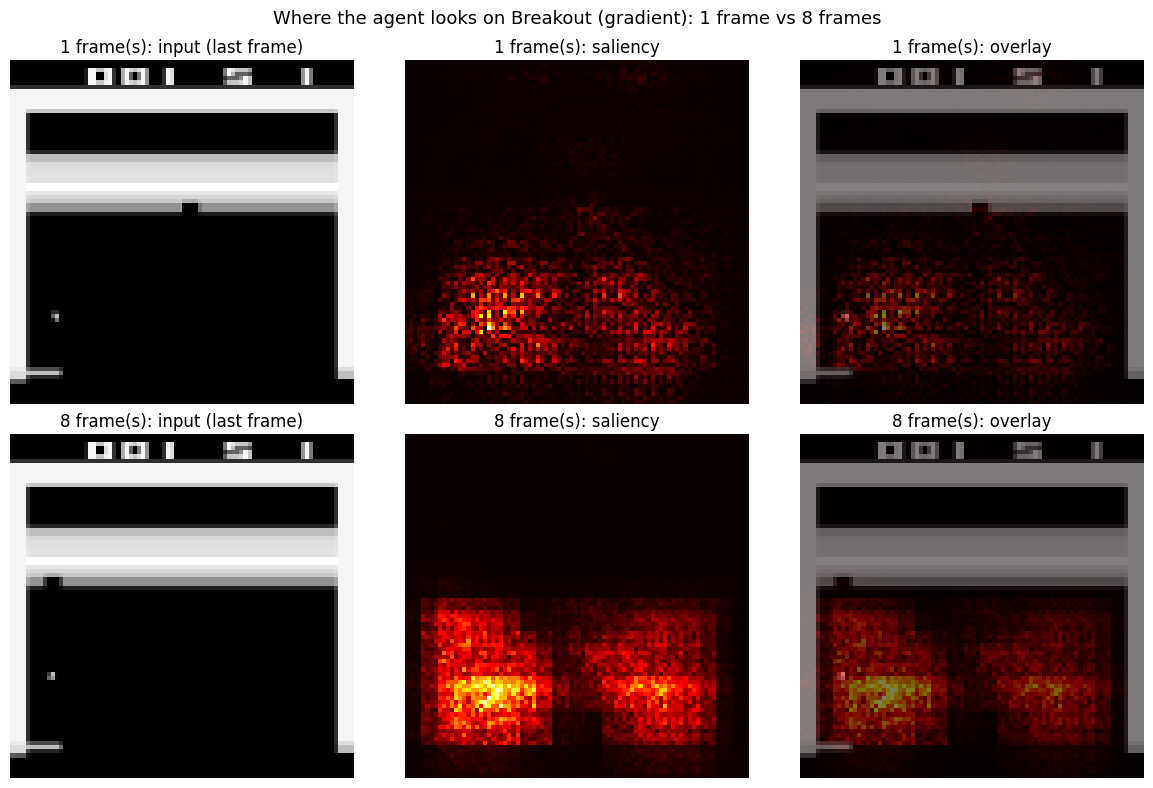

In [15]:
def saliency_gradient(game, frame_stack):
    """Gradient of the chosen action's score w.r.t. input pixels (Simonyan 2014)."""
    model = load_model(game, frame_stack)
    obs = get_observation(game, frame_stack)
    x = torch.from_numpy(obs).unsqueeze(0).float().to(sal_device)
    x.requires_grad_(True)
    logits, _ = model(x)
    a = logits.argmax(dim=1)
    score = logits[0, a]
    model.zero_grad()
    score.backward()
    sal = x.grad.abs()[0].max(dim=0)[0].cpu().numpy()
    sal = (sal - sal.min()) / (sal.max() - sal.min() + 1e-8)
    return obs[-1], sal

GAME = "Breakout"
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for row, fs in enumerate([1, 8]):
    frame, sal = saliency_gradient(GAME, fs)
    axes[row, 0].imshow(frame, cmap="gray"); axes[row, 0].set_title(f"{fs} frame(s): input (last frame)")
    axes[row, 1].imshow(sal, cmap="hot");    axes[row, 1].set_title(f"{fs} frame(s): saliency")
    axes[row, 2].imshow(frame, cmap="gray")
    axes[row, 2].imshow(sal, cmap="hot", alpha=0.5); axes[row, 2].set_title(f"{fs} frame(s): overlay")
    for ax in axes[row]: ax.axis("off")
plt.suptitle(f"Where the agent looks on {GAME} (gradient): 1 frame vs 8 frames", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "saliency_Breakout.png"), dpi=150, bbox_inches="tight")
plt.show()


### 6b. Perturbation saliency (Greydanus et al. 2018)

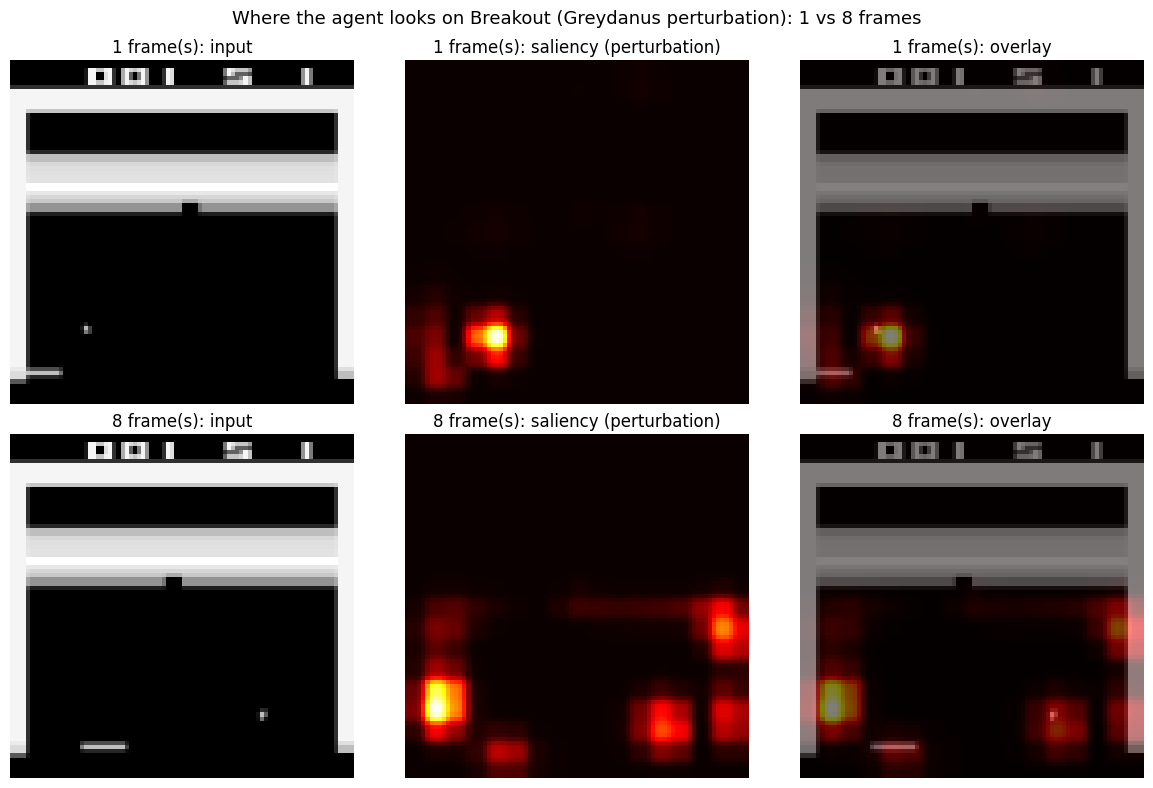

In [17]:
from scipy.ndimage import gaussian_filter

def gaussian_mask(cx, cy, size=IMG_SIZE, sigma2=25.0):
    y, x = np.ogrid[0:size, 0:size]
    m = np.exp(-((x - cx) ** 2 + (y - cy) ** 2) / (2 * sigma2))
    return (m / m.max()).astype(np.float32)

def logits_of(model, obs):
    x = torch.from_numpy(obs).unsqueeze(0).float()
    with torch.no_grad():
        logits, _ = model(x)
    return logits[0].numpy()

def saliency_greydanus(game, frame_stack, stride=5, sigma_blur=3.0):
    """S(i,j) = 1/2 ||logits(I) - logits(I')||^2, I' = current frame blurred around (i,j)."""
    model = load_model(game, frame_stack)
    obs = get_observation(game, frame_stack)
    base_logits = logits_of(model, obs)
    last = obs[-1].astype(np.float32)
    blurred = gaussian_filter(last, sigma=sigma_blur)
    sal = np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.float32)
    for i in range(0, IMG_SIZE, stride):
        for j in range(0, IMG_SIZE, stride):
            M = gaussian_mask(j, i)
            pert_last = last * (1 - M) + blurred * M
            pert = obs.copy().astype(np.float32)
            pert[-1] = pert_last
            l2 = logits_of(model, pert.astype(np.uint8))
            sal[i:i + stride, j:j + stride] = 0.5 * np.sum((base_logits - l2) ** 2)
    sal = (sal - sal.min()) / (sal.max() - sal.min() + 1e-8)
    sal = gaussian_filter(sal, sigma=1.0)
    return obs[-1], sal

GAME = "Breakout"
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for row, fs in enumerate([1, 8]):
    frame, sal = saliency_greydanus(GAME, fs)
    axes[row, 0].imshow(frame, cmap="gray"); axes[row, 0].set_title(f"{fs} frame(s): input")
    axes[row, 1].imshow(sal, cmap="hot");    axes[row, 1].set_title(f"{fs} frame(s): saliency (perturbation)")
    axes[row, 2].imshow(frame, cmap="gray")
    axes[row, 2].imshow(sal, cmap="hot", alpha=0.5); axes[row, 2].set_title(f"{fs} frame(s): overlay")
    for ax in axes[row]: ax.axis("off")
plt.suptitle(f"Where the agent looks on {GAME} (Greydanus perturbation): 1 vs 8 frames", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "saliency_greydanus_Breakout.png"), dpi=150, bbox_inches="tight")
plt.show()
